# Wasserstein Practical-Significance Test: Type I Error and Power

Candidate $F_t = N(\mu_t, \sigma_F^2)$, true system $G_t = N(\mu_t + \text{shift}, \sigma_G^2)$.
For each simulated history we compute $\delta^\star$. The test at radius $\delta$ rejects iff $\delta^\star > \delta$,
so one run gives the rejection rate at every $\delta$:

* $\delta \ge W_1(G_t,F_t)$: $H_0$ true, so the rate is the **Type I error** (should be $\le\alpha$).
* $\delta < W_1(G_t,F_t)$: $H_0$ false, so the rate is the **power**.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import norm
from joblib import Parallel, delayed


def slot_cost(d, T):
    # integral of |u - s| over a slot of width 1/T, u at distance d from the slot midpoint
    w = 1 / T
    return np.where(d <= w / 2, w**2 / 4 + d**2, w * d)


def w1_uniform(u):
    # exact W1 between the empirical distribution of u (last axis) and U(0,1)
    T = u.shape[-1]
    m = (np.arange(1, T + 1) - 0.5) / T
    return slot_cost(np.abs(np.sort(u, axis=-1) - m), T).sum(axis=-1)


def moved_mass(dist, delta, R):
    # greedy transport: move nearest atoms (mass 1/R, cost d/R each) across y, last one fractionally
    d = np.sort(dist, axis=1)
    cum = np.cumsum(d, axis=1) / R
    k = (cum <= delta).sum(axis=1)
    rows = np.arange(len(d))
    spent = np.where(k > 0, cum[rows, np.maximum(k - 1, 0)], 0.0)
    d_next = np.where(k < R, d[rows, np.minimum(k, R - 1)], np.inf)
    with np.errstate(invalid="ignore", divide="ignore"):
        eta = np.where(np.isfinite(d_next), (delta - spent) / d_next, 0.0)
    return k / R + np.clip(eta, 0, 1 / R)


def pit_bounds(y, Ysim, delta):
    # feasible PIT interval [lo_t, hi_t] over the W1 ball of radius delta around the empirical F_t
    R = Ysim.shape[1]
    F = (Ysim <= y[:, None]).mean(axis=1)
    if delta == 0:
        return F, F
    below = np.where(Ysim <= y[:, None], y[:, None] - Ysim, np.inf)  # ties included
    above = np.where(Ysim > y[:, None], Ysim - y[:, None], np.inf)
    return F - moved_mass(below, delta, R), F + moved_mass(above, delta, R)


def w_star(lo, hi):
    # min W1(empirical, U(0,1)) with u_t in [lo_t, hi_t]: exact, via assignment of intervals to slots
    T = len(lo)
    m = (np.arange(1, T + 1) - 0.5) / T
    d = np.maximum(0, np.maximum(lo[:, None] - m, m - hi[:, None]))
    C = slot_cost(d, T)
    r, c = linear_sum_assignment(C)
    return C[r, c].sum()


def delta_star(y, Ysim, c_alpha, tol=1e-3):
    # smallest delta with W*(delta) <= c_alpha (W* is nonincreasing in delta)
    if w_star(*pit_bounds(y, Ysim, 0.0)) <= c_alpha:
        return 0.0
    lo, hi = 0.0, 0.1
    while w_star(*pit_bounds(y, Ysim, hi)) > c_alpha:
        lo, hi = hi, 2 * hi
    while hi - lo > tol:
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if w_star(*pit_bounds(y, Ysim, mid)) > c_alpha else (lo, mid)
    return hi


def w1_normals(a, s1, b, s2):
    # W1(N(a, s1^2), N(b, s2^2)) = E|(a - b) + (s1 - s2) Z|
    m, s = a - b, abs(s1 - s2)
    return abs(m) if s == 0 else m * (2 * norm.cdf(m / s) - 1) + 2 * s * norm.pdf(m / s)

In [23]:
# ---- candidate (simulation) model:  F_t = N(mu_t, SD_F^2)
T = 100                                              # historical periods
mu = np.full(T, 2.0)
SD_F = 1.0
R = 200                                              # simulation replications per period

# ---- true system:  G_t = N(mu_t + SHIFT, SD_G^2)
SHIFT = 0.75
SD_G = 1.0

# ---- test settings
ALPHA = 0.05
M = 1000                                             # simulated histories
DELTAS = [0, 0.01, 0.02, 0.05, 0.1, 0.25, 0.5]       # radii shown in the table
SEED = 0

true W1(G_t, F_t) = 0.750   c_alpha = 0.0583   delta* median = 0.048  (5%-95%: 0.023-0.081)


,delta,H0 true?,rejection rate,95% CI,meaning
0,0.00,no,1.000,"[1.000, 1.000]",power
1,0.01,no,0.997,"[0.994, 1.000]",power
2,0.02,no,0.966,"[0.955, 0.977]",power
3,0.05,no,0.454,"[0.423, 0.485]",power
4,0.10,no,0.013,"[0.006, 0.020]",power
5,0.25,no,0.000,"[0.000, 0.000]",power
6,0.50,no,0.000,"[0.000, 0.000]",power


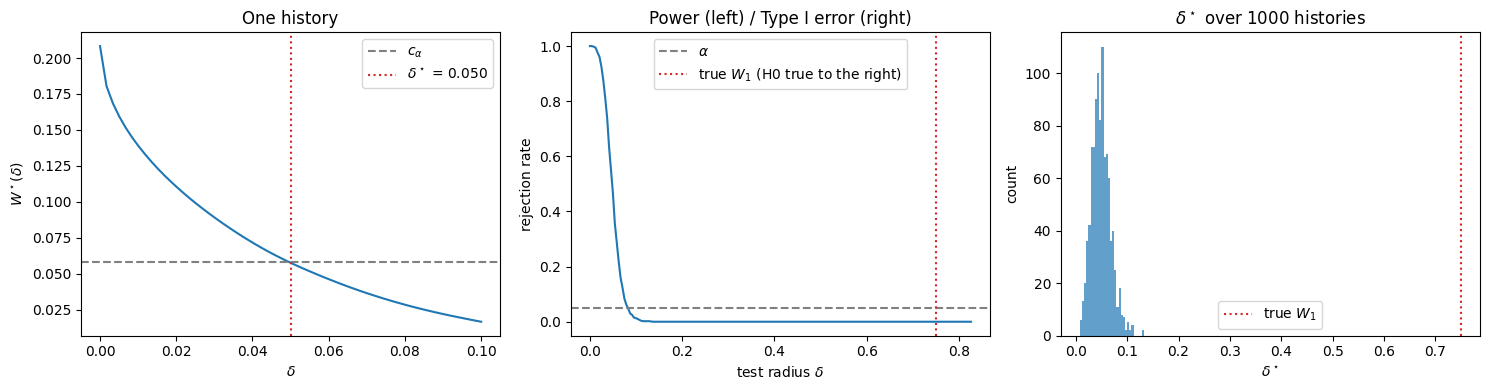

In [24]:
rng = np.random.default_rng(SEED)
true_w1 = w1_normals(SHIFT, SD_G, 0.0, SD_F)
c_alpha = np.quantile(w1_uniform(rng.random((100_000, T))), 1 - ALPHA)


def one_history(seed):
    g = np.random.default_rng(seed)
    y = mu + SHIFT + SD_G * g.standard_normal(T)            # observed trajectory, y_t ~ G_t
    Ysim = mu[:, None] + SD_F * g.standard_normal((T, R))   # R replications from F_t
    return delta_star(y, Ysim, c_alpha)


dstar = np.array(Parallel(n_jobs=-1)(delayed(one_history)(SEED + 1 + i) for i in range(M)))

# ---- table: rejection rate at each radius
rate = np.array([(dstar > d).mean() for d in DELTAS])
se = np.sqrt(rate * (1 - rate) / M)
table = pd.DataFrame({
    "delta": DELTAS,
    "H0 true?": ["yes" if d >= true_w1 else "no" for d in DELTAS],
    "rejection rate": rate,
    "95% CI": [f"[{max(r - 1.96 * s, 0):.3f}, {min(r + 1.96 * s, 1):.3f}]" for r, s in zip(rate, se)],
    "meaning": ["Type I error" if d >= true_w1 else "power" for d in DELTAS],
})
print(f"true W1(G_t, F_t) = {true_w1:.3f}   c_alpha = {c_alpha:.4f}   "
      f"delta* median = {np.median(dstar):.3f}  (5%-95%: {np.quantile(dstar, .05):.3f}-{np.quantile(dstar, .95):.3f})")
display(table.round(3))

# ---- figures
g = np.random.default_rng(SEED + 1)                        # the first history, for panel 1
y = mu + SHIFT + SD_G * g.standard_normal(T)
Ysim = mu[:, None] + SD_F * g.standard_normal((T, R))
grid = np.linspace(0, max(2 * dstar[0], 0.05), 60)
curve = [w_star(*pit_bounds(y, Ysim, d)) for d in grid]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(grid, curve)
ax[0].axhline(c_alpha, ls="--", c="gray", label=r"$c_\alpha$")
ax[0].axvline(dstar[0], ls=":", c="C3", label=rf"$\delta^\star$ = {dstar[0]:.3f}")
ax[0].set(xlabel=r"$\delta$", ylabel=r"$W^\star(\delta)$", title="One history")
ax[0].legend()

d_grid = np.linspace(0, max(true_w1, dstar.max()) * 1.1 + 1e-3, 200)
ax[1].plot(d_grid, [(dstar > d).mean() for d in d_grid])
ax[1].axhline(ALPHA, ls="--", c="gray", label=r"$\alpha$")
ax[1].axvline(true_w1, ls=":", c="C3", label=r"true $W_1$ (H0 true to the right)")
ax[1].set(xlabel=r"test radius $\delta$", ylabel="rejection rate", title="Power (left) / Type I error (right)")
ax[1].legend()

ax[2].hist(dstar, bins=30, color="C0", alpha=0.7)
ax[2].axvline(true_w1, ls=":", c="C3", label=r"true $W_1$")
ax[2].set(xlabel=r"$\delta^\star$", ylabel="count", title=rf"$\delta^\star$ over {M} histories")
ax[2].legend()
plt.tight_layout()
plt.show()